In [1]:
%pip install -q pandas matplotlib pillow imagehash scikit-learn tqdm ipywidgets torch torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os

RAW_DIR = r"D:\Data Mining\Dataset\dataset"
assert os.path.isdir(RAW_DIR), "Folder tidak ditemukan"
print("OK:", RAW_DIR)

OK: D:\Data Mining\Dataset\dataset


In [2]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
is_img = lambda f: os.path.splitext(f)[1].lower() in IMG_EXT

for root, dirs, fs in sorted(os.walk(RAW_DIR)):
    n = sum(is_img(f) for f in fs)
    depth = root[len(RAW_DIR):].count(os.sep)
    if n > 0 or depth <= 2:
        print("  " * depth + os.path.basename(root) + f"/   ({n} gambar)")

dataset/   (0 gambar)
  Calculus/   (0 gambar)
    Calculus/   (1296 gambar)
  Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/   (0 gambar)
    Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/   (0 gambar)
          train/   (1493 gambar)
          val/   (49 gambar)
  Data caries/   (0 gambar)
    Data caries/   (0 gambar)
        preview/   (2382 gambar)
        done/   (219 gambar)
  Gingivitis/   (0 gambar)
    Gingivitis/   (2349 gambar)
  Mouth Ulcer/   (0 gambar)
    Mouth Ulcer/   (0 gambar)
        preview/   (2541 gambar)
        ulcer original dataset/   (265 gambar)
  Tooth Discoloration/   (0 gambar)
    Tooth Discoloration/   (0 gambar)
        preview/   (1834 gambar)
        tooth discoloration original dataset/   (183 gambar)
  hypodontia/   (0 gambar)
    hypodontia/   (1251 gambar)


In [4]:
EXCLUDE_KEYWORDS = ["augment", "preview", "yolo"]
CLASSES = {"caries": "caries", "calculus": "calculus", "gingivitis": "gingivitis"}
NEAR_DUP_THRESHOLD = 6
SEED = 42

In [5]:
import pandas as pd

rows, skipped = [], 0
for root, _, fs in os.walk(RAW_DIR):
    parts = [p.lower() for p in os.path.relpath(root, RAW_DIR).split(os.sep)]
    excluded = any(k in p for p in parts for k in EXCLUDE_KEYWORDS)
    label = None
    for p in reversed(parts):
        for key, name in CLASSES.items():
            if key in p:
                label = name
                break
        if label:
            break
    if label is None:
        continue
    for f in fs:
        if is_img(f):
            if excluded:
                skipped += 1
                continue
            rows.append({"path": os.path.join(root, f), "label": label})

df = pd.DataFrame(rows)
print("Gambar dilewati (preview/yolo/augment):", skipped)
print("Total dipakai:", len(df))
print(df.label.value_counts())

Gambar dilewati (preview/yolo/augment): 3924
Total dipakai: 3864
label
gingivitis    2349
calculus      1296
caries         219
Name: count, dtype: int64


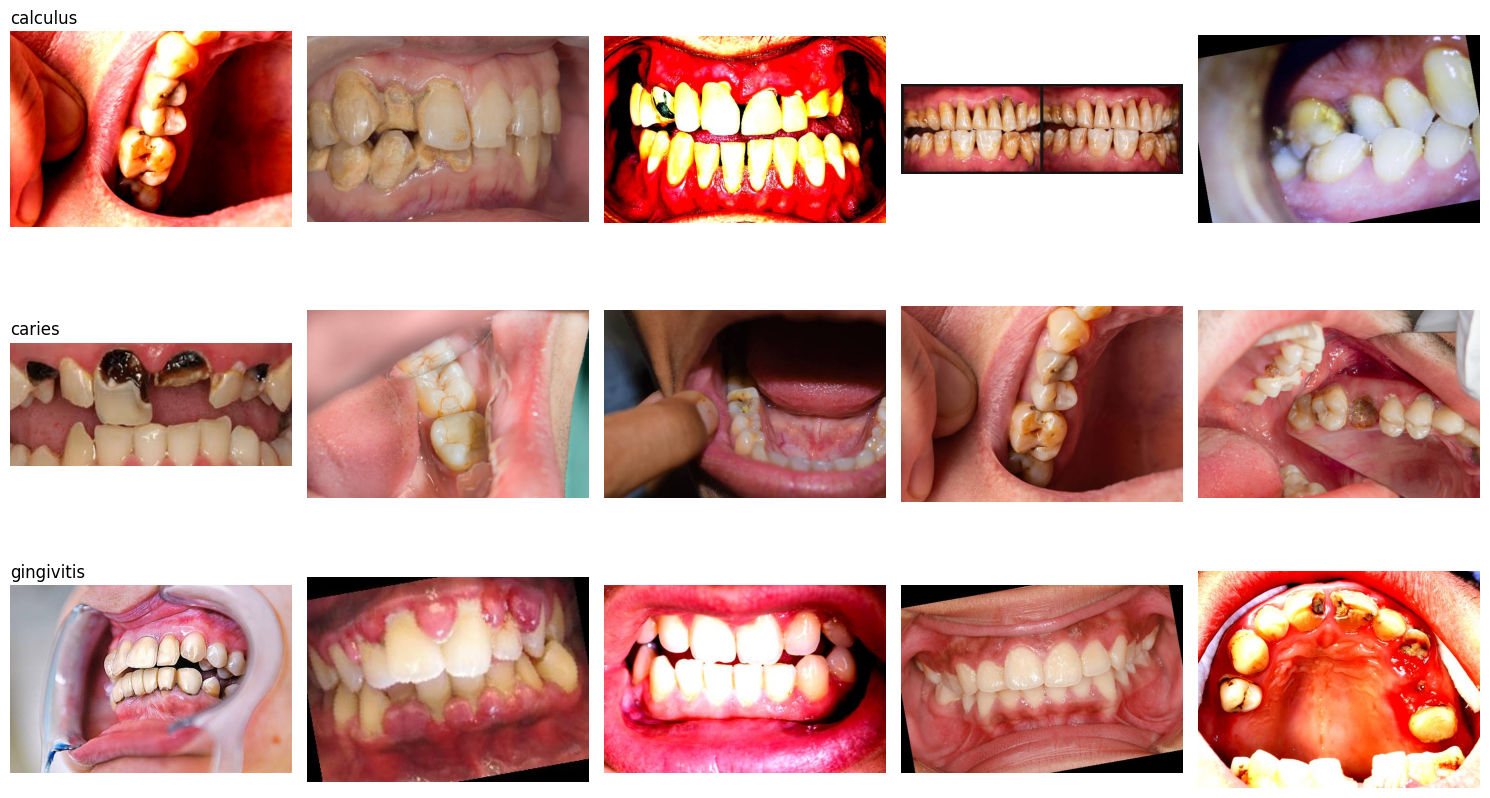

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted(df.label.unique())
fig, axes = plt.subplots(len(classes), 5, figsize=(15, 3 * len(classes)))
for r, c in enumerate(classes):
    sample = df[df.label == c].sample(5, random_state=SEED)
    for k, p in enumerate(sample.path):
        axes[r, k].imshow(Image.open(p).convert("RGB"))
        axes[r, k].axis("off")
        if k == 0:
            axes[r, k].set_title(c, loc="left", fontsize=12)
plt.tight_layout()
plt.show()

In [7]:
import numpy as np
import imagehash
from tqdm.auto import tqdm

H, HF = [], []
for p in tqdm(df.path):
    im = Image.open(p).convert("RGB")
    H.append(imagehash.phash(im).hash.flatten())
    HF.append(imagehash.phash(im.transpose(Image.FLIP_LEFT_RIGHT)).hash.flatten())
A = np.array(H).astype(np.float32)
Af = np.array(HF).astype(np.float32)

def dist(X, Y):
    return 64 - (X @ Y.T + (1 - X) @ (1 - Y).T)

n = len(df)
parent = list(range(n))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

CH = 500
for s in tqdm(range(0, n, CH)):
    blk = A[s:s + CH]
    d = np.minimum(dist(blk, A), dist(blk, Af))
    ii, jj = np.where(d <= NEAR_DUP_THRESHOLD)
    for i, j in zip(ii, jj):
        if s + i < j:
            union(s + i, j)

df["group"] = [find(i) for i in range(n)]
sizes = df.group.value_counts()
imgs_in_dup = sizes[sizes > 1].sum()
print(f"Total gambar        : {n}")
print(f"Kelompok unik       : {len(sizes)}")
print(f"Kelompok berisi >1  : {(sizes > 1).sum()}")
print(f"Gambar yang punya kembaran/mirip: {imgs_in_dup} ({100 * imgs_in_dup / n:.1f}%)")
print("Kelompok dengan label campur:", int((df.groupby('group').label.nunique() > 1).sum()))
print(df.groupby('label').group.nunique())

  0%|          | 0/3864 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Total gambar        : 3864
Kelompok unik       : 1167
Kelompok berisi >1  : 514
Gambar yang punya kembaran/mirip: 3211 (83.1%)
Kelompok dengan label campur: 179
label
calculus      394
caries        190
gingivitis    766
Name: group, dtype: int64


In [8]:
pairs = []
for s in range(0, n, CH):
    blk = A[s:s + CH]
    d = np.minimum(dist(blk, A), dist(blk, Af))
    ii, jj = np.where(d <= 8)
    for i, j in zip(ii, jj):
        if s + i < j:
            pairs.append((s + i, j, d[i, j]))
pairs = np.array(pairs)
print("Pasangan gambar mirip:", len(pairs))

def cluster(th):
    par = list(range(n))
    def f(x):
        while par[x] != x:
            par[x] = par[par[x]]
            x = par[x]
        return x
    for i, j, dd in pairs:
        if dd <= th:
            a, b = f(int(i)), f(int(j))
            if a != b:
                par[b] = a
    return np.array([f(i) for i in range(n)])

for th in [0, 2, 4, 6, 8]:
    g = cluster(th)
    sz = pd.Series(g).value_counts()
    mixed = int((df.assign(g=g).groupby("g").label.nunique() > 1).sum())
    print(f"ambang {th}: kelompok {len(sz)}, terbesar {sz.iloc[0]}, "
          f"punya kembaran {100 * sz[sz > 1].sum() / n:.1f}%, label campur {mixed}")

Pasangan gambar mirip: 20217
ambang 0: kelompok 1776, terbesar 47, punya kembaran 72.5%, label campur 283
ambang 2: kelompok 1515, terbesar 56, punya kembaran 77.4%, label campur 237
ambang 4: kelompok 1301, terbesar 56, punya kembaran 80.7%, label campur 195
ambang 6: kelompok 1167, terbesar 56, punya kembaran 83.1%, label campur 179
ambang 8: kelompok 1103, terbesar 56, punya kembaran 84.4%, label campur 175


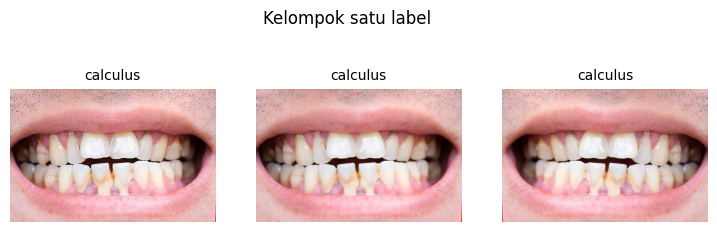

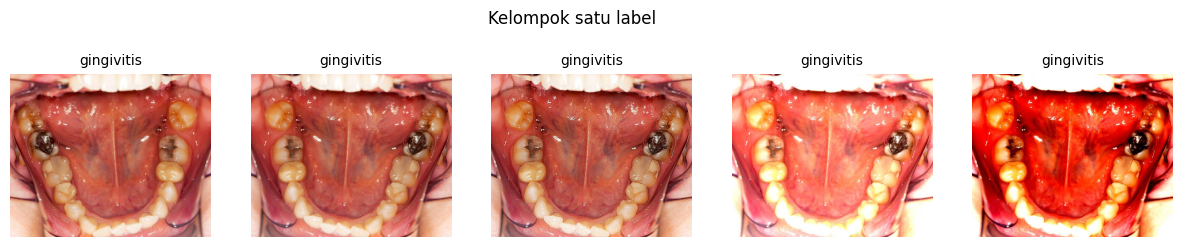

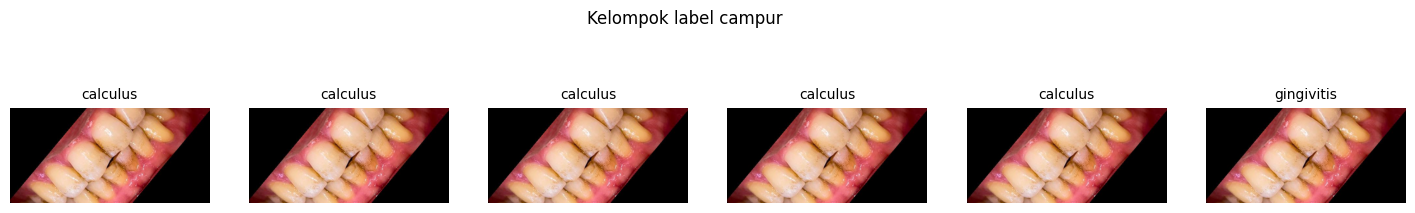

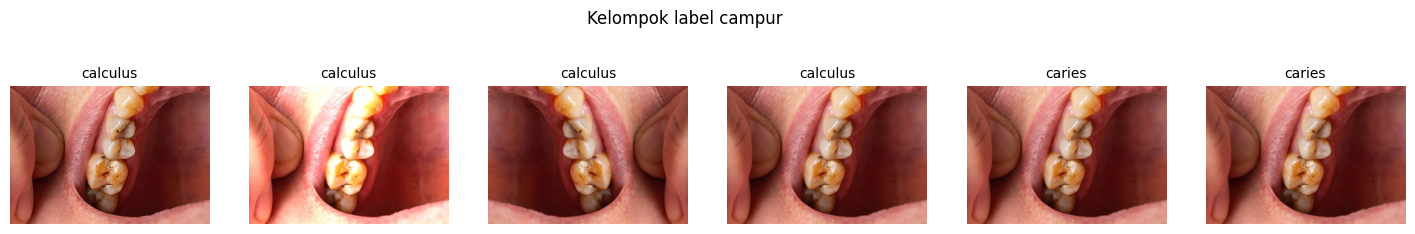

In [9]:
g4 = cluster(4)
tmp = df.assign(g=g4)
multi = tmp.groupby("g").filter(lambda x: len(x) >= 3)
mixed_groups = [k for k, v in multi.groupby("g") if v.label.nunique() > 1]
plain_groups = [k for k, v in multi.groupby("g") if v.label.nunique() == 1]

def show(gid, title):
    sub = tmp[tmp.g == gid].head(6)
    fig, axes = plt.subplots(1, len(sub), figsize=(3 * len(sub), 3))
    axes = np.atleast_1d(axes)
    for ax, (_, row) in zip(axes, sub.iterrows()):
        ax.imshow(Image.open(row.path).convert("RGB"))
        ax.set_title(row.label, fontsize=10)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()

import random
random.seed(1)
for gid in random.sample(plain_groups, min(2, len(plain_groups))):
    show(gid, "Kelompok satu label")
for gid in random.sample(mixed_groups, min(2, len(mixed_groups))):
    show(gid, "Kelompok label campur")